<a href="https://colab.research.google.com/github/Narmadha-H/CSA0653/blob/main/ML10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iter  0: log-likelihood = -1620.569, means = [2.258 7.27 ]
Iter  5: log-likelihood = -1076.899, means = [1.987 7.116]
Iter 10: log-likelihood = -1075.845, means = [1.953 7.039]
Iter 15: log-likelihood = -1075.795, means = [1.945 7.02 ]
Iter 20: log-likelihood = -1075.792, means = [1.944 7.016]
Iter 25: log-likelihood = -1075.792, means = [1.943 7.015]
Converged after 30 iterations

Estimated parameters
  Component: mean = 1.943, std = 0.906, weight = 0.596
  Component: mean = 7.014, std = 1.526, weight = 0.404
True values : means 2 and 7, std 1.0 and 1.5, weights 0.6 and 0.4


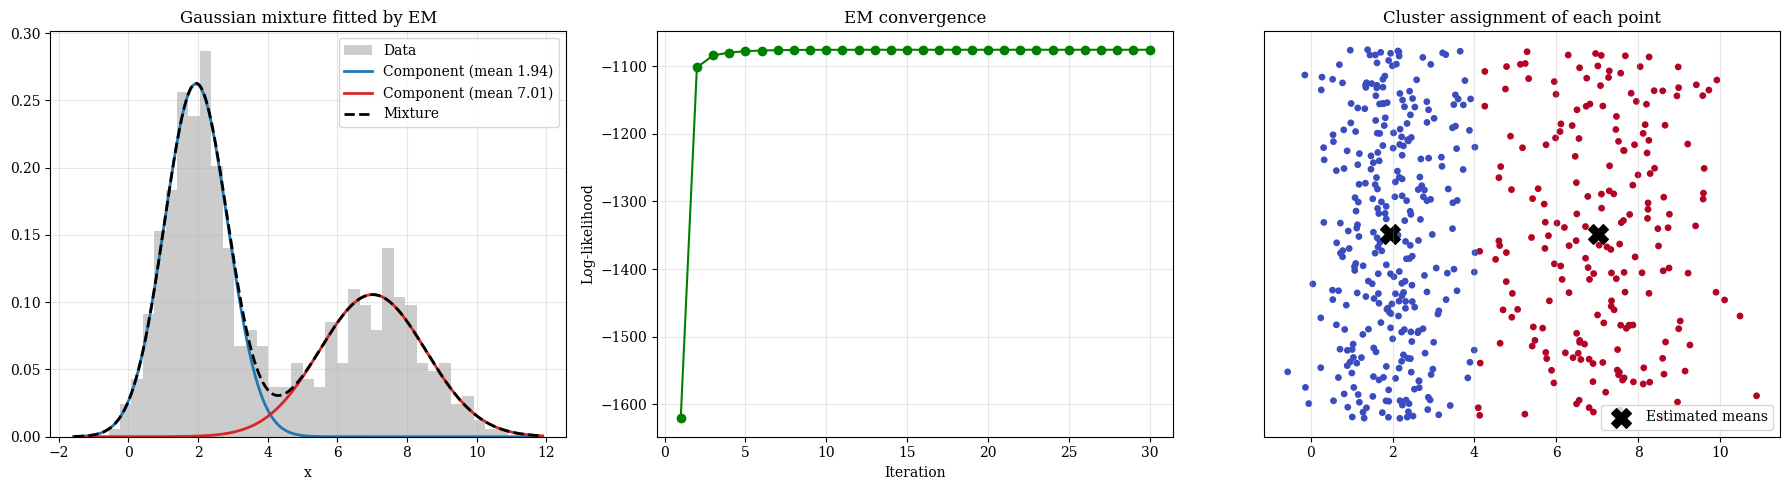

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"

rng = np.random.default_rng(42)
data = np.concatenate([rng.normal(2, 1.0, 300), rng.normal(7, 1.5, 200)])   # hidden true groups
N, K = len(data), 2

def gauss(x, m, v):
    return np.exp(-(x - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v)

# Initial guess
mu  = np.array([data.min(), data.max()])
var = np.full(K, data.var())
pi  = np.full(K, 1 / K)

log_lik = []
for it in range(100):
    # ---- E-step: responsibilities
    dens = np.array([pi[k] * gauss(data, mu[k], var[k]) for k in range(K)])   # shape (K, N)
    ll = np.sum(np.log(dens.sum(axis=0)))
    resp = dens / dens.sum(axis=0)

    # ---- M-step: update parameters
    Nk  = resp.sum(axis=1)
    mu  = (resp * data).sum(axis=1) / Nk
    var = (resp * (data - mu[:, None]) ** 2).sum(axis=1) / Nk
    pi  = Nk / N

    log_lik.append(ll)
    if it % 5 == 0:
        print(f"Iter {it:2d}: log-likelihood = {ll:.3f}, means = {np.round(mu, 3)}")
    if it > 0 and abs(log_lik[-1] - log_lik[-2]) < 1e-6:
        print(f"Converged after {it+1} iterations")
        break

order = np.argsort(mu)
print("\nEstimated parameters")
for k in order:
    print(f"  Component: mean = {mu[k]:.3f}, std = {np.sqrt(var[k]):.3f}, weight = {pi[k]:.3f}")
print("True values : means 2 and 7, std 1.0 and 1.5, weights 0.6 and 0.4")

labels = np.argmax(resp, axis=0)

# ---- Graphs
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
xs = np.linspace(data.min() - 1, data.max() + 1, 400)
ax[0].hist(data, bins=35, density=True, alpha=.4, color="gray", label="Data")
mix = np.zeros_like(xs)
for k, col in zip(order, ["tab:blue", "tab:red"]):
    comp = pi[k] * gauss(xs, mu[k], var[k]); mix += comp
    ax[0].plot(xs, comp, color=col, lw=2, label=f"Component (mean {mu[k]:.2f})")
ax[0].plot(xs, mix, "k--", lw=2, label="Mixture")
ax[0].set_title("Gaussian mixture fitted by EM"); ax[0].set_xlabel("x"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(range(1, len(log_lik) + 1), log_lik, "o-", color="green")
ax[1].set_xlabel("Iteration"); ax[1].set_ylabel("Log-likelihood")
ax[1].set_title("EM convergence"); ax[1].grid(alpha=.3)

ax[2].scatter(data, rng.uniform(-0.1, 0.1, N), c=labels, cmap="coolwarm", s=15)
ax[2].scatter(mu, [0, 0], c="k", marker="X", s=200, label="Estimated means")
ax[2].set_yticks([]); ax[2].set_title("Cluster assignment of each point"); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()